In [28]:
from google.colab import drive

In [29]:
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
ls drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/4_ML/

trends.csv  Trends.ipynb


In [31]:
import pandas as pd
import numpy as np

In [32]:
# Load the historical search trends dataset
df = pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/4_ML/trends.csv")

In [33]:
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (26955, 5)


,location,year,category,rank,query
0,Global,2001,Consumer Brands,1,Nokia
1,Global,2001,Consumer Brands,2,Sony
2,Global,2001,Consumer Brands,3,BMW
3,Global,2001,Consumer Brands,4,Palm
4,Global,2001,Consumer Brands,5,Adobe


In [34]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26955 entries, 0 to 26954
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   location  26955 non-null  object
 1   year      26955 non-null  int64 
 2   category  26955 non-null  object
 3   rank      26955 non-null  int64 
 4   query     26955 non-null  object
dtypes: int64(2), object(3)
memory usage: 1.0+ MB


None

In [35]:

# Check missing values and duplicates
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

# Inspect how rankings are distributed
display(df["rank"].value_counts().sort_index())


Missing values:


,0
location,0
year,0
category,0
rank,0
query,0


Duplicate rows: 10


,count
rank,
1,5391
2,5391
3,5391
4,5391
5,5391


In [36]:

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Remove leading/trailing whitespace
for col in ["location", "category", "query"]:
    df[col] = df[col].str.strip()

# Create the binary classification target
df["top_3"] = (df["rank"] <= 3).astype(int)

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (26945, 6)


,location,year,category,rank,query,top_3
0,Global,2001,Consumer Brands,1,Nokia,1
1,Global,2001,Consumer Brands,2,Sony,1
2,Global,2001,Consumer Brands,3,BMW,1
3,Global,2001,Consumer Brands,4,Palm,0
4,Global,2001,Consumer Brands,5,Adobe,0


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

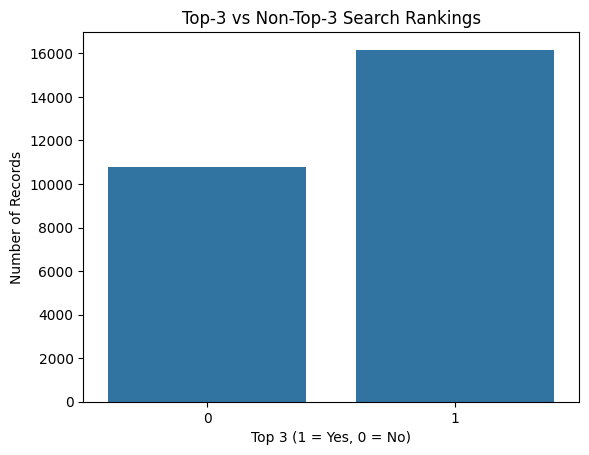

,proportion
top_3,
1,60.0
0,40.0


In [38]:
# Compare Top-3 and non-Top-3 records
sns.countplot(data=df, x="top_3")

plt.title("Top-3 vs Non-Top-3 Search Rankings")
plt.xlabel("Top 3 (1 = Yes, 0 = No)")
plt.ylabel("Number of Records")
plt.show()

# Check target proportions
display(df["top_3"].value_counts(normalize=True) * 100)

In [39]:

# Features and target
X = df[["location", "year", "category", "query"]]
y = df["rank"]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (26945, 4)
Target: (26945,)


In [40]:

# Train on historical years, test on future years
train_mask = df["year"] <= 2017
test_mask = df["year"] >= 2018

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 18810
Testing records: 8135


In [41]:
#Encode features and train
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

In [42]:
# Convert categorical and text features into numeric features
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["location", "category"]),
    ("text", TfidfVectorizer(ngram_range=(1, 2)),
     "query"),
    ("numeric", StandardScaler(), ["year"])
])

In [43]:
# Build a leakage-safe pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

# Learn from historical data
model.fit(X_train, y_train)

print("Regression model trained successfully!")

Regression model trained successfully!


**Important functions:**
- OneHotEncoder() converts categorical values into numeric indicators.
- TfidfVectorizer() converts search-query text into numerical features.
- StandardScaler() standardizes the year feature.
- Ridge() fits regularized linear regression.
- Pipeline() ensures feature transformations are learned only from training data.

In [44]:
#Predict and calculate metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [45]:
# Predict rankings
y_pred = model.predict(X_test)

# Compare against a simple baseline: always predict rank 3
baseline_pred = np.full(len(y_test), 3.0)

In [46]:
results = pd.DataFrame({
    "Model": ["Baseline", "Ridge Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred)
    ]
})

display(results.round(4))


,Model,MAE,RMSE,R2
0,Baseline,1.2000,1.4142,0.0000
1,Ridge Regression,1.2146,1.4114,0.0039


How to interpret the metrics

**Metric	Meaning	Better value**

MAE	Average absolute ranking error	Lower

RMSE	Penalizes larger ranking errors	Lower

R²	Improvement over predicting the mean	Higher

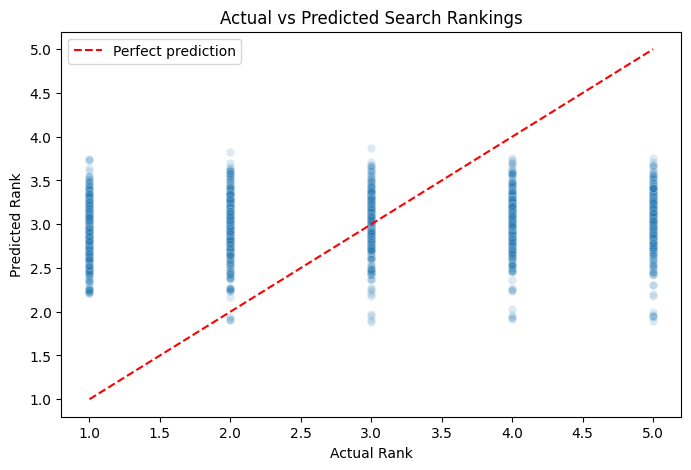

In [47]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.15
)

plt.plot([1, 5], [1, 5], "r--", label="Perfect prediction")

plt.xlabel("Actual Rank")
plt.ylabel("Predicted Rank")
plt.title("Actual vs Predicted Search Rankings")
plt.legend()
plt.show()


In [48]:
#Generate the analytical conclusion


baseline_mae = results.loc[0, "MAE"]
model_mae = results.loc[1, "MAE"]

improvement = (
    (baseline_mae - model_mae) / baseline_mae
) * 100

print(f"MAE improvement over baseline: {improvement:.2f}%")

if improvement > 0:
    print("Conclusion: Ridge outperforms the baseline.")
elif improvement < 0:
    print("Conclusion: Ridge underperforms the baseline.")
else:
    print("Conclusion: Ridge matches the baseline.")


MAE improvement over baseline: -1.22%
Conclusion: Ridge underperforms the baseline.


In [50]:
from sklearn.linear_model import LogisticRegression

In [52]:
# Use the same features
X = df[["location", "year", "category", "query"]]
y = df["top_3"]

In [53]:
# Chronological train/test split
train_mask = df["year"] <= 2017
test_mask = df["year"] >= 2018

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

display(y_train.value_counts(normalize=True))

Training: (18810, 4)
Testing: (8135, 4)


,proportion
top_3,
1,0.6
0,0.4


In [54]:

# Reuse the preprocessing design from Exercise 2
classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

classifier.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


**Important functions:**
- LogisticRegression() predicts the probability of belonging to class 1.
- max_iter=1000 allows additional optimization iterations if needed.
- fit() learns patterns from the training data.
- Pipeline() prevents preprocessing from being fitted on test data.

In [55]:

# Predicted classes: 0 or 1
y_pred = classifier.predict(X_test)

# Probability that each query belongs to Top 3
y_prob = classifier.predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    "Query": X_test["query"].values,
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Top_3_Probability": y_prob
}).head(10))


,Query,Actual,Predicted,Top_3_Probability
0,World Cup,1,1,0.683271
1,Avicii,1,0,0.304765
2,Mac Miller,1,1,0.582704
3,Stan Lee,0,1,0.622744
4,Black Panther,0,1,0.715497
5,World Cup,1,1,0.706130
6,Hurricane Florence,1,1,0.675383
7,Mega Millions Result,1,1,0.576876
8,Royal Wedding,0,1,0.706281
9,Election Results,0,1,0.637072


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [57]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.5717
Precision: 0.6023
Recall: 0.8422
F1 Score: 0.7024

Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.17      0.24      3254
           1       0.60      0.84      0.70      4881

    accuracy                           0.57      8135
   macro avg       0.51      0.50      0.47      8135
weighted avg       0.53      0.57      0.52      8135



**Metric	Business interpretation**

Accuracy	How often predictions are correct

Precision	Of predicted Top-3 queries, how many actually ranked Top 3?

Recall	Of actual Top-3 queries, how many did we identify?

F1	Balance between Precision and Recall

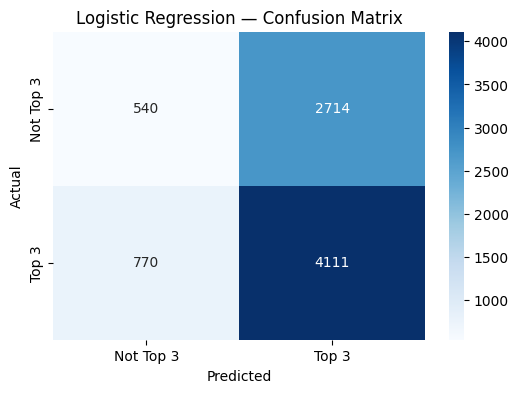

In [58]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Top 3", "Top 3"],
    yticklabels=["Not Top 3", "Top 3"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()


In [60]:

# Majority-class baseline: always predict Top 3
baseline_pred = np.ones(len(y_test), dtype=int)

comparison = pd.DataFrame({
    "Model": ["Majority Baseline", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        precision_score(y_test, baseline_pred),
        precision_score(y_test, y_pred)
    ],
    "Recall": [
        recall_score(y_test, baseline_pred),
        recall_score(y_test, y_pred)
    ],
    "F1": [
        f1_score(y_test, baseline_pred),
        f1_score(y_test, y_pred)
    ]
})

display(comparison.round(4))

if comparison.loc[1, "F1"] > comparison.loc[0, "F1"]:
    print("Conclusion: Logistic Regression beats the baseline on F1.")
else:
    print("Conclusion: Logistic Regression does not beat the baseline on F1.")


,Model,Accuracy,Precision,Recall,F1
0,Majority Baseline,0.6000,0.6000,1.0000,0.7500
1,Logistic Regression,0.5717,0.6023,0.8422,0.7024


Conclusion: Logistic Regression does not beat the baseline on F1.


In [61]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.base import clone


In [63]:

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    )
}


**Important parameters:**
- max_depth: Limits tree complexity to reduce overfitting.
- n_estimators: Number of trees in an ensemble.
- min_samples_leaf: Minimum training samples in a leaf.
- learning_rate: Controls how much each new XGBoost tree contributes.

In [64]:

trained_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name}: Training completed")


Decision Tree: Training completed
Random Forest: Training completed
XGBoost: Training completed


In [65]:

from sklearn.metrics import roc_auc_score

results_ml = []

# Include Logistic Regression from Exercise 3
all_models = {
    "Logistic Regression": classifier,
    **trained_models
}

for name, model in all_models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results_ml.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results_ml)

display(
    comparison_df.sort_values("ROC-AUC", ascending=False)
                 .round(4)
)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.5717,0.6023,0.8422,0.7024,0.5215
2,Random Forest,0.6000,0.6000,1.0000,0.7500,0.5164
3,XGBoost,0.5952,0.5989,0.9848,0.7449,0.5049
1,Decision Tree,0.6000,0.6000,1.0000,0.7500,0.4989


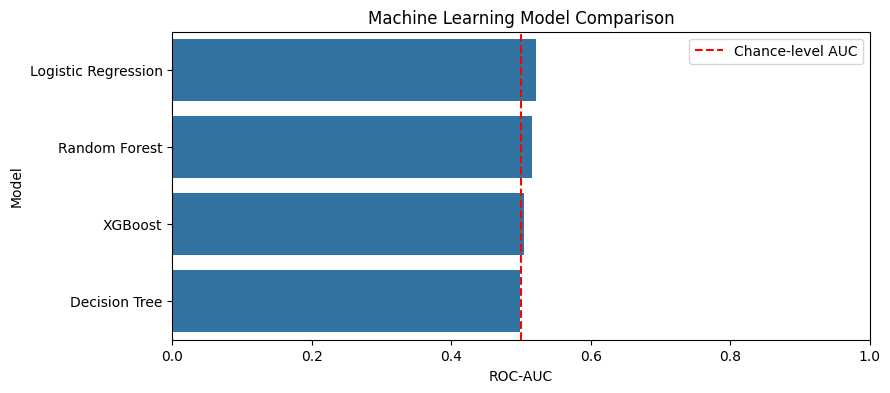

In [66]:

plt.figure(figsize=(9, 4))

sns.barplot(
    data=comparison_df.sort_values("ROC-AUC", ascending=False),
    x="ROC-AUC",
    y="Model"
)

plt.axvline(
    0.5,
    color="red",
    linestyle="--",
    label="Chance-level AUC"
)

plt.xlim(0, 1)
plt.title("Machine Learning Model Comparison")
plt.legend()
plt.show()


In [67]:

best_row = comparison_df.loc[
    comparison_df["ROC-AUC"].idxmax()
]

best_model_name = best_row["Model"]

print("Best Model:", best_model_name)
print("ROC-AUC:", round(best_row["ROC-AUC"], 4))
print("F1 Score:", round(best_row["F1"], 4))

best_model = all_models[best_model_name]


Best Model: Logistic Regression
ROC-AUC: 0.5215
F1 Score: 0.7024


In [68]:

from sklearn.model_selection import TimeSeriesSplit

# Sort historical training data chronologically
train_df = df.loc[df["year"] <= 2017].sort_values("year")

X_cv = train_df[["location", "year", "category", "query"]]
y_cv = train_df["top_3"]

# Create 5 chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

print("Training records:", len(X_cv))
print("Number of folds:", tscv.get_n_splits())


Training records: 18810
Number of folds: 5


In [69]:

# Every validation period must be later than its training period
validation_years = [2013, 2014, 2015, 2016, 2017]

cv_splits = []

for year in validation_years:
    train_idx = np.flatnonzero(
        X_cv["year"].to_numpy() < year
    )

    val_idx = np.flatnonzero(
        X_cv["year"].to_numpy() == year
    )

    if len(train_idx) and len(val_idx):
        cv_splits.append((train_idx, val_idx))

print("Valid folds:", len(cv_splits))

for train_idx, val_idx in cv_splits:
    print(
        "Train through:",
        X_cv.iloc[train_idx]["year"].max(),
        "| Validate on:",
        X_cv.iloc[val_idx]["year"].unique()
    )


Valid folds: 5
Train through: 2012 | Validate on: [2013]
Train through: 2013 | Validate on: [2014]
Train through: 2014 | Validate on: [2015]
Train through: 2015 | Validate on: [2016]
Train through: 2016 | Validate on: [2017]


In [70]:

from sklearn.model_selection import cross_validate

cv_results = []

for name, model in all_models.items():

    scores = cross_validate(
        clone(model),
        X_cv,
        y_cv,
        cv=cv_splits,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "CV_F1": scores["test_f1"].mean(),
        "CV_Precision": scores["test_precision"].mean(),
        "CV_Recall": scores["test_recall"].mean(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_AUC_Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values("CV_ROC_AUC", ascending=False)
         .round(4)
)


,Model,CV_F1,CV_Precision,CV_Recall,CV_ROC_AUC,CV_AUC_Std
0,Logistic Regression,0.7169,0.6052,0.8799,0.5214,0.0109
3,XGBoost,0.7474,0.6007,0.9891,0.5085,0.0058
2,Random Forest,0.7500,0.6000,1.0000,0.5021,0.0110
1,Decision Tree,0.7494,0.5999,0.9984,0.5013,0.0022


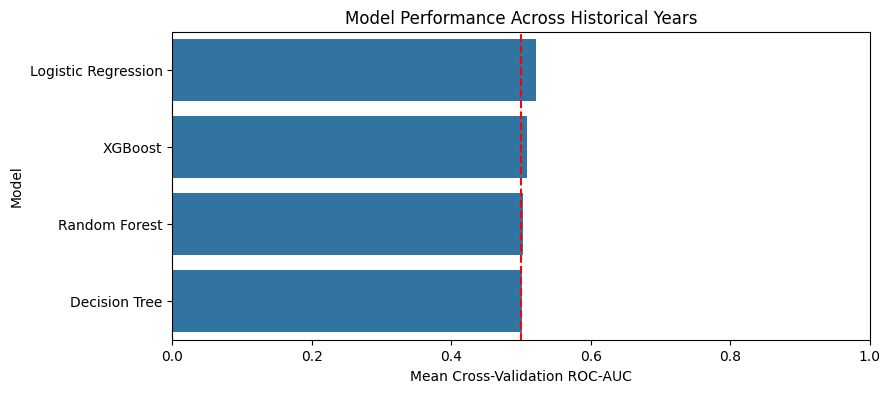

In [71]:

plt.figure(figsize=(9, 4))

sns.barplot(
    data=cv_df.sort_values("CV_ROC_AUC", ascending=False),
    x="CV_ROC_AUC",
    y="Model"
)

plt.axvline(0.5, color="red", linestyle="--")

plt.xlabel("Mean Cross-Validation ROC-AUC")
plt.title("Model Performance Across Historical Years")
plt.xlim(0, 1)
plt.show()


In [72]:

best_cv_row = cv_df.loc[
    cv_df["CV_ROC_AUC"].idxmax()
]

selected_name = best_cv_row["Model"]

print("Selected model:", selected_name)
print("Mean CV ROC-AUC:", round(best_cv_row["CV_ROC_AUC"], 4))
print("CV AUC Std:", round(best_cv_row["CV_AUC_Std"], 4))


Selected model: Logistic Regression
Mean CV ROC-AUC: 0.5214
CV AUC Std: 0.0109


Test Precision: 0.6023
Test Recall: 0.8422
Test F1: 0.7024
Test ROC-AUC: 0.5215


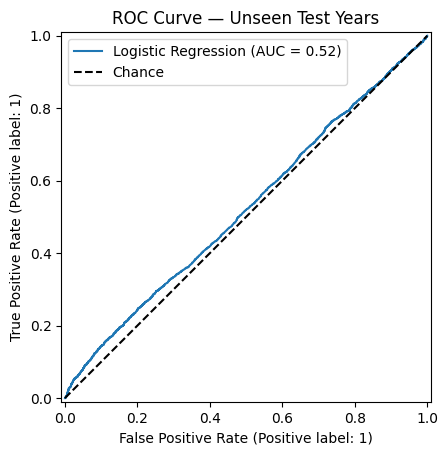

In [73]:

from sklearn.metrics import roc_curve, RocCurveDisplay

# Train selected model on all pre-2018 records
final_model = clone(all_models[selected_name])
final_model.fit(X_train, y_train)

test_pred = final_model.predict(X_test)
test_prob = final_model.predict_proba(X_test)[:, 1]

print("Test Precision:", round(precision_score(y_test, test_pred), 4))
print("Test Recall:", round(recall_score(y_test, test_pred), 4))
print("Test F1:", round(f1_score(y_test, test_pred), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

RocCurveDisplay.from_predictions(
    y_test,
    test_prob,
    name=selected_name
)

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("ROC Curve — Unseen Test Years")
plt.legend()
plt.show()


In [74]:

cv_auc = best_cv_row["CV_ROC_AUC"]
test_auc = roc_auc_score(y_test, test_prob)

gap = cv_auc - test_auc

print(f"CV ROC-AUC: {cv_auc:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Generalization gap: {gap:.4f}")

if gap > 0.05:
    print("Warning: Test performance is noticeably lower.")
elif gap < -0.05:
    print("Test performance exceeds historical CV performance.")
else:
    print("CV and test performance are relatively close.")


CV ROC-AUC: 0.5214
Test ROC-AUC: 0.5215
Generalization gap: -0.0001
CV and test performance are relatively close.


In [75]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

param_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 15, 20],
        "model__min_samples_leaf": [5, 10, 20]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100, 150],
        "model__max_depth": [5, 10, 15],
        "model__min_samples_leaf": [5, 10]
    },

    "XGBoost": {
        "model__n_estimators": [50, 100, 150],
        "model__max_depth": [3, 5, 7],
        "model__learning_rate": [0.01, 0.05, 0.1]
    }
}

print("Selected algorithm:", selected_name)


Selected algorithm: Logistic Regression


In [76]:

# Select the algorithm chosen in Exercise 5
base_model = clone(all_models[selected_name])

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_spaces[selected_name],
    n_iter=8,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=42,
    n_jobs=1,
    refit=True
)

# Tune using historical training data only
search.fit(X_cv, y_cv)

print("Best Parameters:")
print(search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(search.best_score_, 4))


Best Parameters:
{'model__class_weight': 'balanced', 'model__C': 0.01}

Best CV ROC-AUC:
0.5243


**Key functions:**
- n_iter=8: Tries up to eight sampled parameter combinations.
- scoring="roc_auc": Optimizes ranking discrimination.
- cv=cv_splits: Uses our five historical validation folds.
- refit=True: Retrains the best configuration on all historical training records.
- best_params_: Returns the winning parameter combination.
- best_score_: Returns its mean cross-validation ROC-AUC.

In [77]:

tuning_results = pd.DataFrame(search.cv_results_)

display(
    tuning_results[
        ["rank_test_score", "mean_test_score",
         "std_test_score", "params"]
    ].sort_values("rank_test_score")
     .round(4)
)


,rank_test_score,mean_test_score,std_test_score,params
1,1,0.5243,0.0103,"{'model__class_weight': 'balanced', 'model__C'..."
0,2,0.5235,0.0101,"{'model__class_weight': None, 'model__C': 0.01}"
3,3,0.5230,0.0110,"{'model__class_weight': 'balanced', 'model__C'..."
2,4,0.5229,0.0109,"{'model__class_weight': None, 'model__C': 0.1}"
4,5,0.5214,0.0109,"{'model__class_weight': None, 'model__C': 1}"
5,6,0.5206,0.0111,"{'model__class_weight': 'balanced', 'model__C'..."
6,7,0.5190,0.0146,"{'model__class_weight': None, 'model__C': 10}"
7,8,0.5178,0.0147,"{'model__class_weight': 'balanced', 'model__C'..."


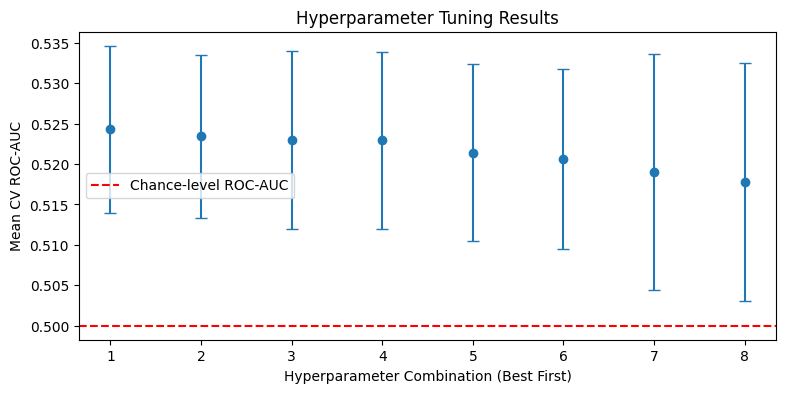

In [78]:

plot_df = tuning_results.sort_values(
    "rank_test_score"
).reset_index(drop=True)

plt.figure(figsize=(9, 4))

plt.errorbar(
    range(1, len(plot_df) + 1),
    plot_df["mean_test_score"],
    yerr=plot_df["std_test_score"],
    fmt="o",
    capsize=4
)

plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Chance-level ROC-AUC"
)

plt.xlabel("Hyperparameter Combination (Best First)")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Hyperparameter Tuning Results")
plt.legend()
plt.show()


In [79]:

from sklearn.metrics import roc_auc_score, f1_score

# Original selected model from Exercise 5
original_model = clone(all_models[selected_name])
original_model.fit(X_cv, y_cv)

# Best model from hyperparameter tuning
tuned_model = search.best_estimator_

evaluation = []

for name, model in {
    "Original": original_model,
    "Tuned": tuned_model
}.items():

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    evaluation.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "F1": f1_score(y_test, pred)
    })

evaluation_df = pd.DataFrame(evaluation)

display(evaluation_df.round(4))


,Model,ROC-AUC,F1
0,Original,0.5215,0.7024
1,Tuned,0.5193,0.2551


In [80]:

original_auc = evaluation_df.loc[0, "ROC-AUC"]
tuned_auc = evaluation_df.loc[1, "ROC-AUC"]

improvement = tuned_auc - original_auc

print(f"ROC-AUC change: {improvement:+.4f}")

if improvement > 0:
    print("Tuning improved test ROC-AUC.")
elif improvement < 0:
    print("Tuning reduced test ROC-AUC.")
else:
    print("Tuning produced no ROC-AUC improvement.")


ROC-AUC change: -0.0021
Tuning reduced test ROC-AUC.


In [81]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Keep distinct non-empty search queries
queries = (
    df["query"]
    .dropna()
    .str.strip()
    .drop_duplicates()
)

queries = queries[queries != ""].reset_index(drop=True)

print("Unique queries:", len(queries))
display(queries.head(10))


Unique queries: 18431


,query
0,Nokia
1,Sony
2,BMW
3,Palm
4,Adobe
5,Nostradamus
6,Osama bin Laden
7,Eminem
8,Michael Jackson
9,Howard Stern


In [82]:

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    min_df=2,
    ngram_range=(1, 2)
)

X_text = vectorizer.fit_transform(queries)

print("TF-IDF matrix:", X_text.shape)


TF-IDF matrix: (18431, 3000)


**Important functions:**
- TfidfVectorizer() converts text into numerical features.
- stop_words="english" removes common English words.
- max_features=3000 limits vocabulary size.
- min_df=2 ignores terms appearing in only one query.
- ngram_range=(1, 2) considers individual words and two-word phrases.

In [83]:

from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    batch_size=1024,
    n_init=10
)

clusters = kmeans.fit_predict(X_text)

cluster_df = pd.DataFrame({
    "query": queries,
    "cluster": clusters
})

display(cluster_df.head(10))


,query,cluster
0,Nokia,0
1,Sony,0
2,BMW,0
3,Palm,0
4,Adobe,0
5,Nostradamus,0
6,Osama bin Laden,0
7,Eminem,0
8,Michael Jackson,0
9,Howard Stern,0


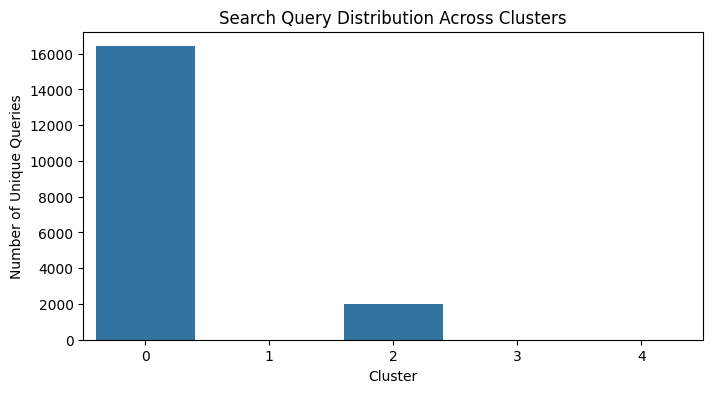

,count
cluster,
0,16408
1,1
2,2014
3,5
4,3


In [84]:

plt.figure(figsize=(8, 4))

sns.countplot(
    data=cluster_df,
    x="cluster",
    order=sorted(cluster_df["cluster"].unique())
)

plt.title("Search Query Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Unique Queries")
plt.show()

display(
    cluster_df["cluster"]
    .value_counts()
    .sort_index()
)


In [85]:

import numpy as np

feature_names = vectorizer.get_feature_names_out()

for cluster_id in range(kmeans.n_clusters):

    center = kmeans.cluster_centers_[cluster_id]

    top_indices = np.argsort(center)[-8:][::-1]
    keywords = feature_names[top_indices]

    print(f"\nCLUSTER {cluster_id}")
    print("Keywords:", ", ".join(keywords))

    # Find queries closest to this cluster's center
    member_idx = np.flatnonzero(clusters == cluster_id)

    distances = kmeans.transform(X_text[member_idx])[
        :, cluster_id
    ]

    closest_idx = member_idx[np.argsort(distances)[:5]]

    for query in queries.iloc[closest_idx]:
        print("-", query)



CLUSTER 0
Keywords: 2014, wat, je, iphone, 2020, comment, ist, 2017
- Kauai
- Tania Dalton
- Pikelets
- Moji Olaiya
- Dugong

CLUSTER 1
Keywords: sinh, google, good friday, good, gomez, gomes, golden, goedkoop
- Ký Sinh Trùng

CLUSTER 2
Keywords: qué, cómo, es, qué es, la, el, 2016, 2015
- Qué es difteria
- Qué es ciencia
- Qué es Kiwi
- Qué es un testudo
- ¿Qué es isquemia?

CLUSTER 3
Keywords: เช, kerry, google, good friday, good, gomez, gomes, golden
- เชือกวิเศษ
- เชียงตุง
- เต้ย เชียร์
- เชียงใหม่
- วิธีเช็คพัสดุ Kerry

CLUSTER 4
Keywords: wie wird, wird, der, wie, 2016, wird das, wetter, das
- Wie wird der Sommer 2016?
- Wie wird das Wetter heute?
- Wie wird das Wetter?


In [86]:

# Attach cluster labels to historical records
cluster_lookup = dict(zip(queries, clusters))

analysis_df = df.copy()

analysis_df["cluster"] = (
    analysis_df["query"].str.strip().map(cluster_lookup)
)

cluster_summary = (
    analysis_df.groupby("cluster")
    .agg(
        total_records=("query", "size"),
        unique_queries=("query", "nunique"),
        top3_rate=("top_3", "mean"),
        countries_regions=("location", "nunique")
    )
    .reset_index()
)

cluster_summary["top3_rate"] *= 100

display(
    cluster_summary.sort_values(
        "top3_rate", ascending=False
    ).round(2)
)


,cluster,total_records,unique_queries,top3_rate,countries_regions
1,1,1,1,100.00,1
3,3,6,5,83.33,1
2,2,2637,2014,62.84,75
0,0,24297,16408,59.69,83
4,4,4,3,50.00,2


In [87]:

largest = cluster_summary.loc[
    cluster_summary["unique_queries"].idxmax()
]

highest_top3 = cluster_summary.loc[
    cluster_summary["top3_rate"].idxmax()
]

print("Largest topic cluster:", int(largest["cluster"]))
print("Unique queries:", int(largest["unique_queries"]))

print("\nHighest historical Top-3 representation:")
print("Cluster:", int(highest_top3["cluster"]))
print("Top-3 rate:", round(highest_top3["top3_rate"], 2), "%")

print("\nBusiness conclusion:")
print(
    "Investigate these clusters further using recent search "
    "volume, market demand, competition, and customer data "
    "before making startup investment decisions."
)


Largest topic cluster: 0
Unique queries: 16408

Highest historical Top-3 representation:
Cluster: 1
Top-3 rate: 100.0 %

Business conclusion:
Investigate these clusters further using recent search volume, market demand, competition, and customer data before making startup investment decisions.
